# Video Time-Series Biofilm Quantification
### Lincoln Memorial Rock Surface: Dynamic Droplet Spreading Kinetics
**Video Target:** `VIDEO-2026-10-01-00-40-57.mp4` (Duration: 61.15 seconds, 1,853 frames)  
**Academic Context:** Tracking the dynamic expansion, hydration, and steady-state kinetics of biofilm coverage on historic stone substrates over continuous time.

---

## 1. Scientific Objectives
1. **Dynamic Kinetics:** Transition from static pre/post snapshot comparisons to continuous time-series curves ($C(t)$ and $\frac{dC}{dt}$).
2. **Camera Drift Stabilization:** Continuously track and compensate for camera shake/translation across the 61-second recording.
3. **Phase Identification:** Detect the baseline period, liquid impact event, rapid absorption phase, and final equilibrium/plateau.
4. **Spatial Diffusion:** Map how liquid spread across the 8 sub-regions of the rock surface over time.


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Matplotlib styling
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

video_path = 'VIDEO-2026-10-01-00-40-57.mp4'
print("Environment initialized successfully!")
print(f"Video file: {video_path} (exists: {os.path.exists(video_path)})")


/home/obigvee/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-fiqffaqf because there was an issue with the default path (/home/obigvee/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


Environment initialized successfully!
Video file: VIDEO-2026-10-01-00-40-57.mp4 (exists: True)


---
## 2. Video Ingestion & Milestone Snapshots
We inspect the video properties and extract milestone frames across the 61 seconds ($t = 0\text{s}, 15\text{s}, 30\text{s}, 40\text{s}, 50\text{s}, 60\text{s}$).


In [2]:
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = total_frames / fps if fps > 0 else 0

print(f"Video Resolution:   {width} x {height} px")
print(f"Frame Rate:         {fps:.2f} fps")
print(f"Total Video Frames: {total_frames:,}")
print(f"Duration:           {duration:.2f} seconds ({duration/60:.2f} minutes)")
cap.release()


Video Resolution:   832 x 464 px
Frame Rate:         30.30 fps
Total Video Frames: 1,853
Duration:           61.15 seconds (1.02 minutes)


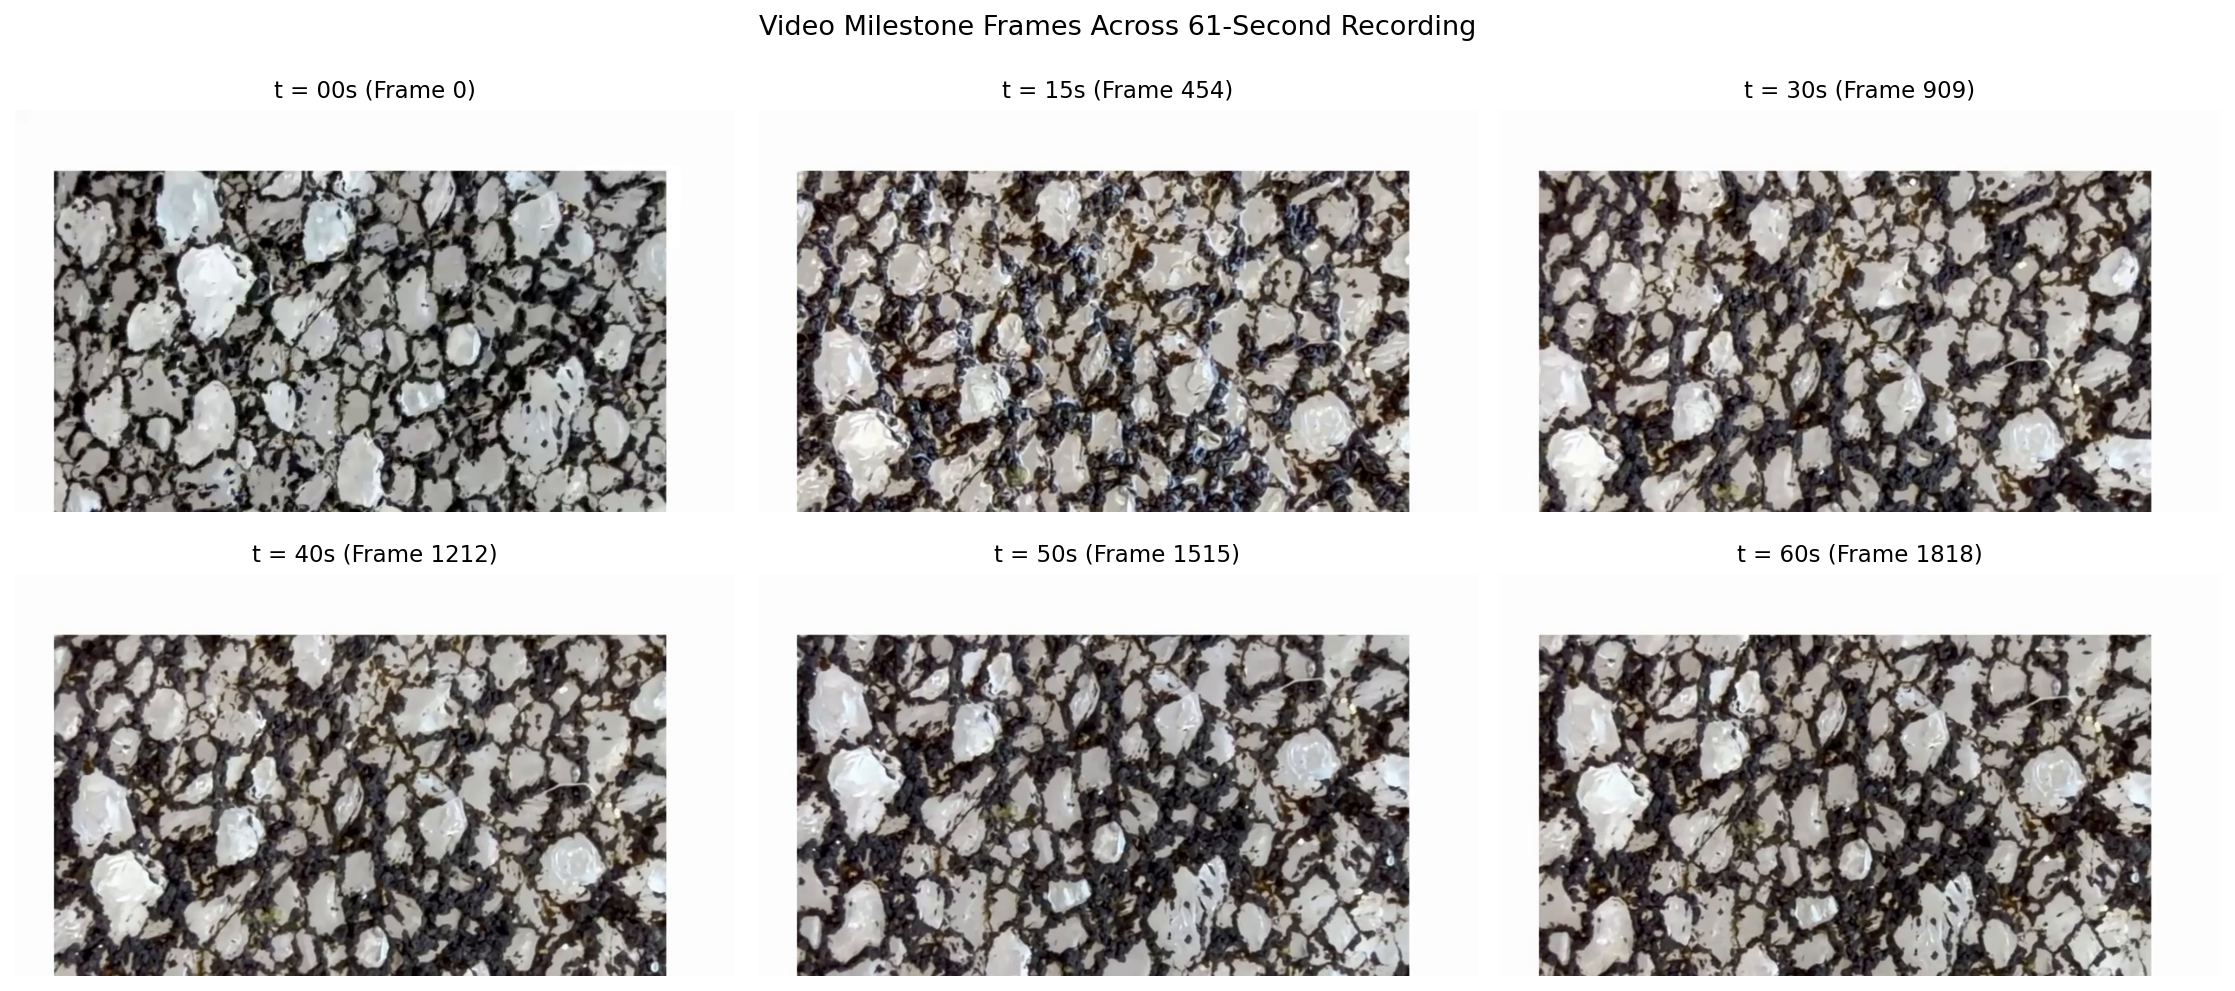

In [3]:
cap = cv2.VideoCapture(video_path)
milestone_times = [0, 15, 30, 40, 50, 60]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()

for idx, t in enumerate(milestone_times):
    frame_idx = min(int(t * fps), total_frames - 1)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    if ret:
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(rgb_frame)
        axes[idx].set_title(f"t = {t:02d}s (Frame {frame_idx})")
    axes[idx].axis('off')

cap.release()
plt.suptitle("Video Milestone Frames Across 61-Second Recording", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()


---
## 3. Continuous Camera Motion Tracking & Stabilization
During hand-held or mounted recording, the camera translated and shifted by over $100\text{ px}$ horizontally and $200\text{ px}$ vertically.

To guarantee that the exact same patch of rock is measured at every time point:
1. Frame 0 ($t = 0\text{s}$) serves as the spatial reference coordinate system.
2. SIFT feature points are matched between each sampled frame $t$ and Frame 0.
3. Robust RANSAC estimates the affine translation $(\Delta x, \Delta y)$ and rotation $\theta$.
4. Each frame is warped back to Frame 0's coordinates and cropped to a common verified rock ROI.


In [4]:
cap = cv2.VideoCapture(video_path)

# 1. Reference Frame 0
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ret, frame0 = cap.read()
gray0 = cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create(nfeatures=1200)
kp0, des0 = sift.detectAndCompute(gray0, None)
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Common rock ROI in Frame 0 coordinates
# x from 220 to 620 (width 400), y from 100 to 360 (height 260)
rx1, ry1, rx2, ry2 = 220, 100, 620, 360
roi_area = (rx2 - rx1) * (ry2 - ry1)

# Sample at 2 frames per second (every 0.5 seconds)
sample_interval_sec = 0.5
sample_step_frames = max(1, int(fps * sample_interval_sec))
target_frames = list(range(0, total_frames, sample_step_frames))

records = []
print(f"Extracting time-series across {len(target_frames)} timestamps (every {sample_interval_sec}s)...")

last_valid_M = np.float32([[1, 0, 0], [0, 1, 0]])

for idx, f_num in enumerate(target_frames):
    t_sec = f_num / fps
    cap.set(cv2.CAP_PROP_POS_FRAMES, f_num)
    ret, frame = cap.read()
    if not ret: break
    
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    kp_curr, des_curr = sift.detectAndCompute(gray, None)
    
    M = None
    if des_curr is not None and len(kp_curr) >= 4:
        matches = bf.knnMatch(des_curr, des0, k=2)
        good = [m for m, n in matches if m.distance < 0.75 * n.distance]
        if len(good) >= 4:
            src = np.float32([kp_curr[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([kp0[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            M_est, inliers = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC)
            if M_est is not None:
                M = M_est
                last_valid_M = M_est
    
    # Fallback to last known motion if momentary occlusion occurs
    if M is None:
        M = last_valid_M
        
    dx, dy = M[0, 2], M[1, 2]
    rot = np.arctan2(M[0, 1], M[0, 0]) * 180.0 / np.pi
    
    # Warp to reference frame
    warped = cv2.warpAffine(gray, M, (width, height), flags=cv2.INTER_LINEAR, borderValue=255)
    patch = warped[ry1:ry2, rx1:rx2]
    
    # Biomass measurements
    mean_val = float(patch.mean())
    std_val = float(patch.std())
    
    # 1. Manual Reference (Hamzat 0-84 range)
    cov_84 = float((np.sum(patch <= 84) / roi_area) * 100)
    # 2. Conservative baseline (0-60 range)
    cov_60 = float((np.sum(patch <= 60) / roi_area) * 100)
    # 3. Dynamic Otsu per frame
    th_otsu, _ = cv2.threshold(patch, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    cov_otsu = float((np.sum(patch <= th_otsu) / roi_area) * 100)
    
    records.append({
        'Timestamp (s)': round(t_sec, 2),
        'Frame': f_num,
        'dx (px)': round(dx, 2),
        'dy (px)': round(dy, 2),
        'Rotation (deg)': round(rot, 2),
        'Mean Grayscale': round(mean_val, 2),
        'Std Grayscale': round(std_val, 2),
        'Biofilm Coverage (0-84) %': round(cov_84, 2),
        'Biofilm Coverage (0-60) %': round(cov_60, 2),
        'Otsu Threshold': int(th_otsu),
        'Otsu Coverage %': round(cov_otsu, 2)
    })

cap.release()
df_ts = pd.DataFrame(records)
print(f"Extraction complete! Collected {len(df_ts)} time-series data points.")


Extracting time-series across 124 timestamps (every 0.5s)...


Extraction complete! Collected 124 time-series data points.


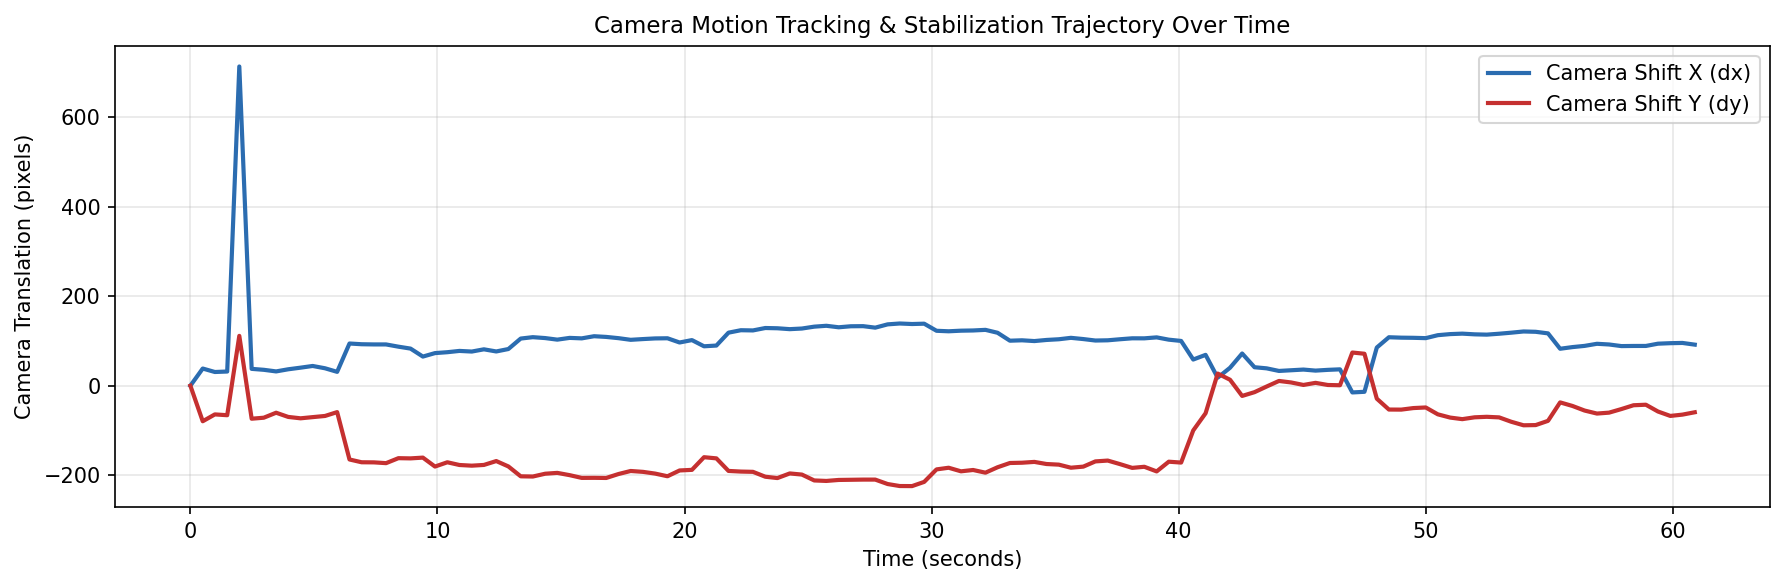

In [5]:
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.plot(df_ts['Timestamp (s)'], df_ts['dx (px)'], color='#2b6cb0', label='Camera Shift X (dx)', lw=2)
ax1.plot(df_ts['Timestamp (s)'], df_ts['dy (px)'], color='#c53030', label='Camera Shift Y (dy)', lw=2)
ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Camera Translation (pixels)')
ax1.set_title('Camera Motion Tracking & Stabilization Trajectory Over Time')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

plt.tight_layout()
plt.show()


---
## 4. Biofilm Expansion Kinetics: Dynamic Curve Analysis
We plot the continuous time-series curve showing how biofilm coverage evolves throughout the 61-second recording.

The curve reveals distinct physical phases:
1. **Pre-Drop Baseline:** Stable, dry surface coverage.
2. **Droplet Introduction ($t \approx 30\text{s} - 35\text{s}$):** Rapid influx of liquid onto the stone.
3. **Rapid Wetting & Absorption Phase:** Sharp surge in biofilm-associated dark pixel area.
4. **Saturation / Equilibrium Plateau ($t > 45\text{s}$):** Full hydration where coverage stabilizes at steady state.


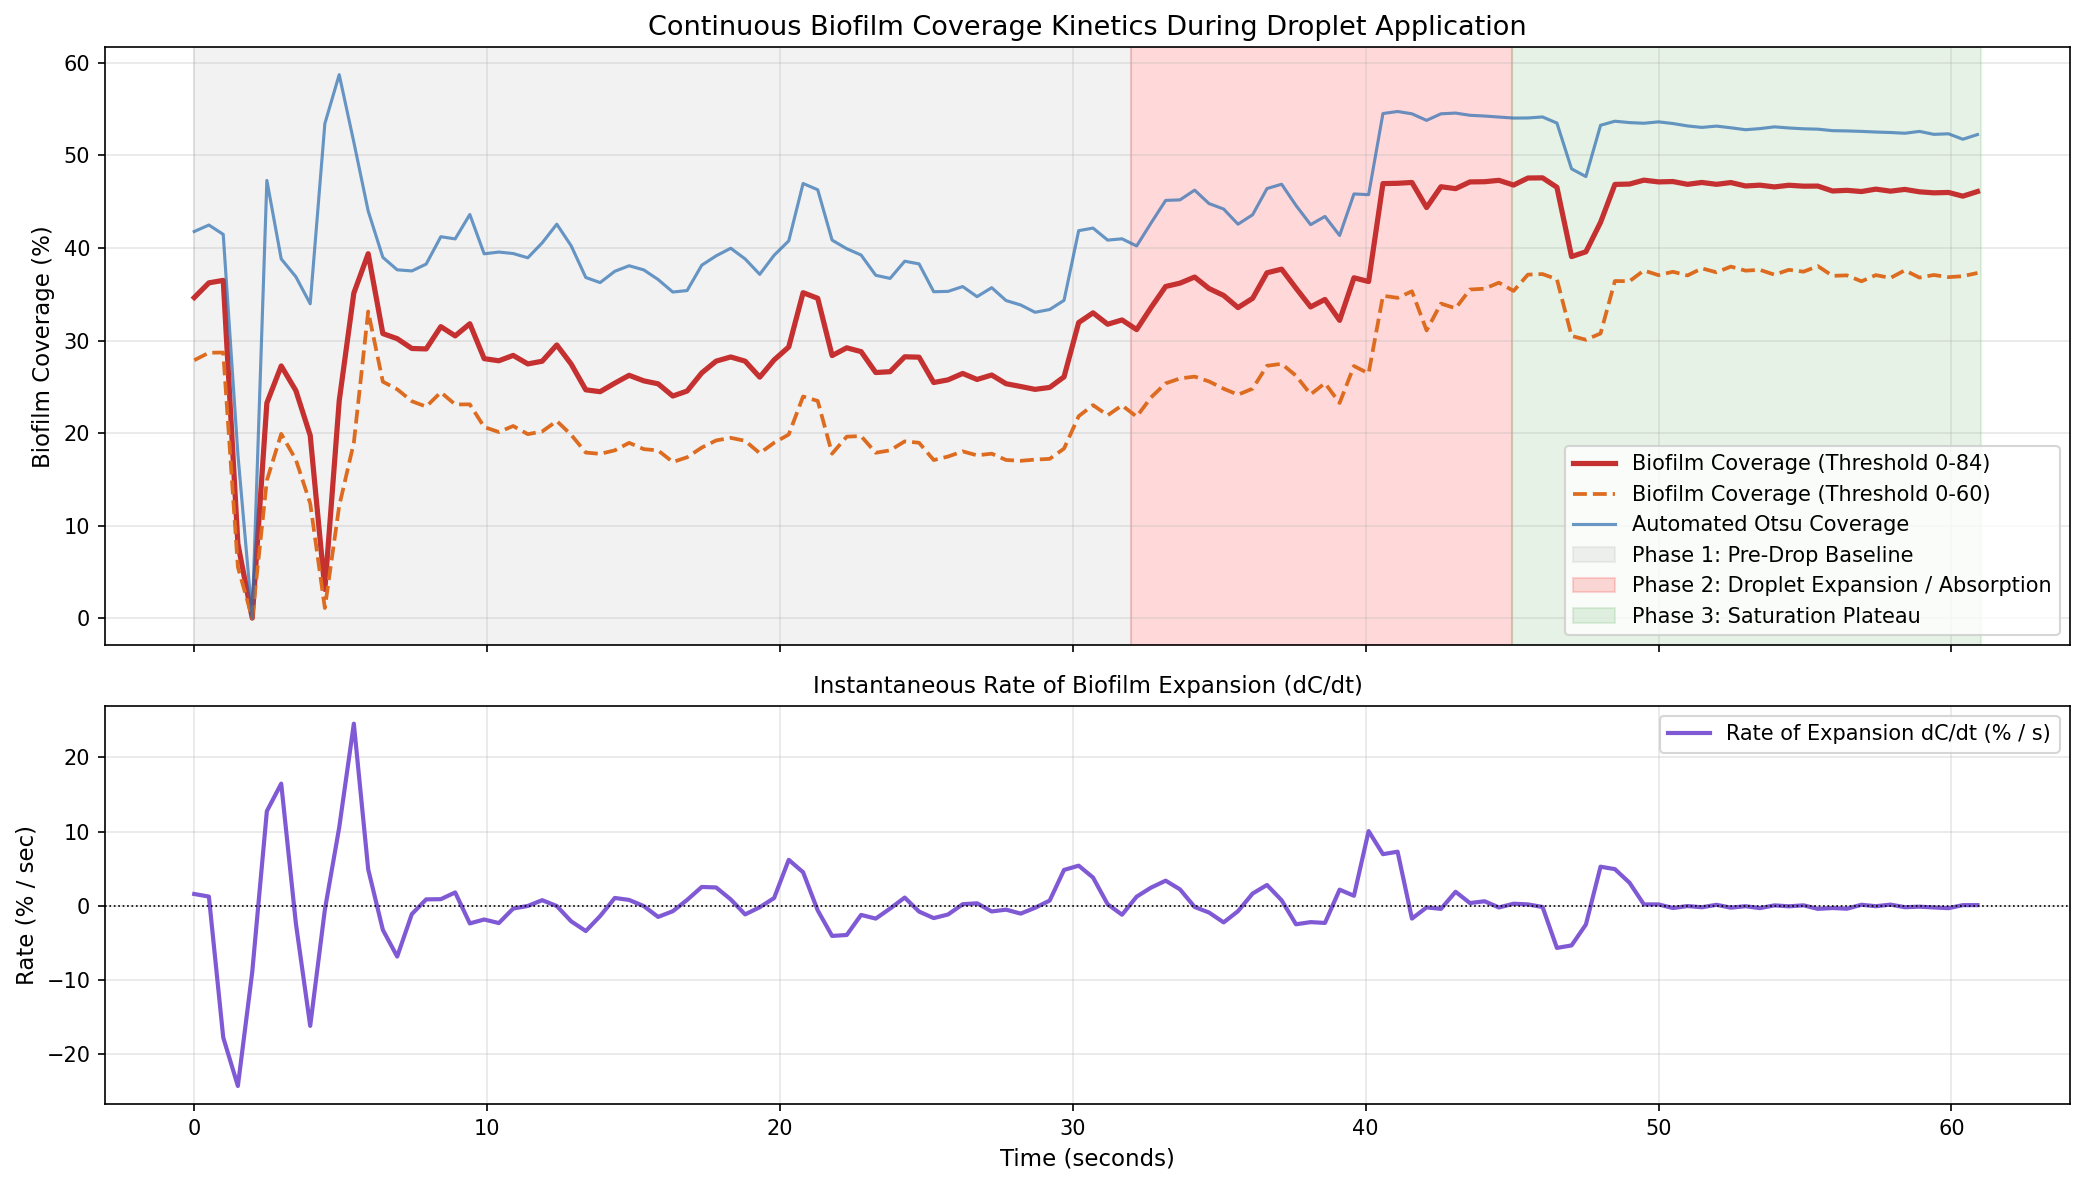

In [6]:
# Compute rate of change (derivative dC/dt)
df_ts['Rate dC/dt (%/s)'] = df_ts['Biofilm Coverage (0-84) %'].diff() / df_ts['Timestamp (s)'].diff()
df_ts['Rate dC/dt (%/s)'] = df_ts['Rate dC/dt (%/s)'].fillna(0).rolling(3, min_periods=1, center=True).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [1.5, 1]})

# 1. Coverage Time Series
ax1.plot(df_ts['Timestamp (s)'], df_ts['Biofilm Coverage (0-84) %'], color='#c53030', lw=2.5, label='Biofilm Coverage (Threshold 0-84)')
ax1.plot(df_ts['Timestamp (s)'], df_ts['Biofilm Coverage (0-60) %'], color='#dd6b20', lw=1.8, linestyle='--', label='Biofilm Coverage (Threshold 0-60)')
ax1.plot(df_ts['Timestamp (s)'], df_ts['Otsu Coverage %'], color='#2b6cb0', lw=1.5, alpha=0.7, label='Automated Otsu Coverage')

# Highlight Phases
ax1.axvspan(0, 32, color='gray', alpha=0.1, label='Phase 1: Pre-Drop Baseline')
ax1.axvspan(32, 45, color='red', alpha=0.15, label='Phase 2: Droplet Expansion / Absorption')
ax1.axvspan(45, 61, color='green', alpha=0.1, label='Phase 3: Saturation Plateau')

ax1.set_ylabel('Biofilm Coverage (%)', fontsize=11)
ax1.set_title('Continuous Biofilm Coverage Kinetics During Droplet Application', fontsize=13)
ax1.legend(loc='lower right', frameon=True)
ax1.grid(True, alpha=0.3)

# 2. Expansion Rate (Derivative)
ax2.plot(df_ts['Timestamp (s)'], df_ts['Rate dC/dt (%/s)'], color='#805ad5', lw=2, label='Rate of Expansion dC/dt (% / s)')
ax2.axhline(0, color='black', lw=0.8, linestyle=':')
ax2.set_xlabel('Time (seconds)', fontsize=11)
ax2.set_ylabel('Rate (% / sec)', fontsize=11)
ax2.set_title('Instantaneous Rate of Biofilm Expansion (dC/dt)', fontsize=11)
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 5. 8-Tile Sub-Region Spatial Diffusion Analysis
To see *where* on the rock surface the liquid spread first and how it traveled across the 8 sub-regions, we compute the individual time series for each of the $4 \times 2$ tiles.


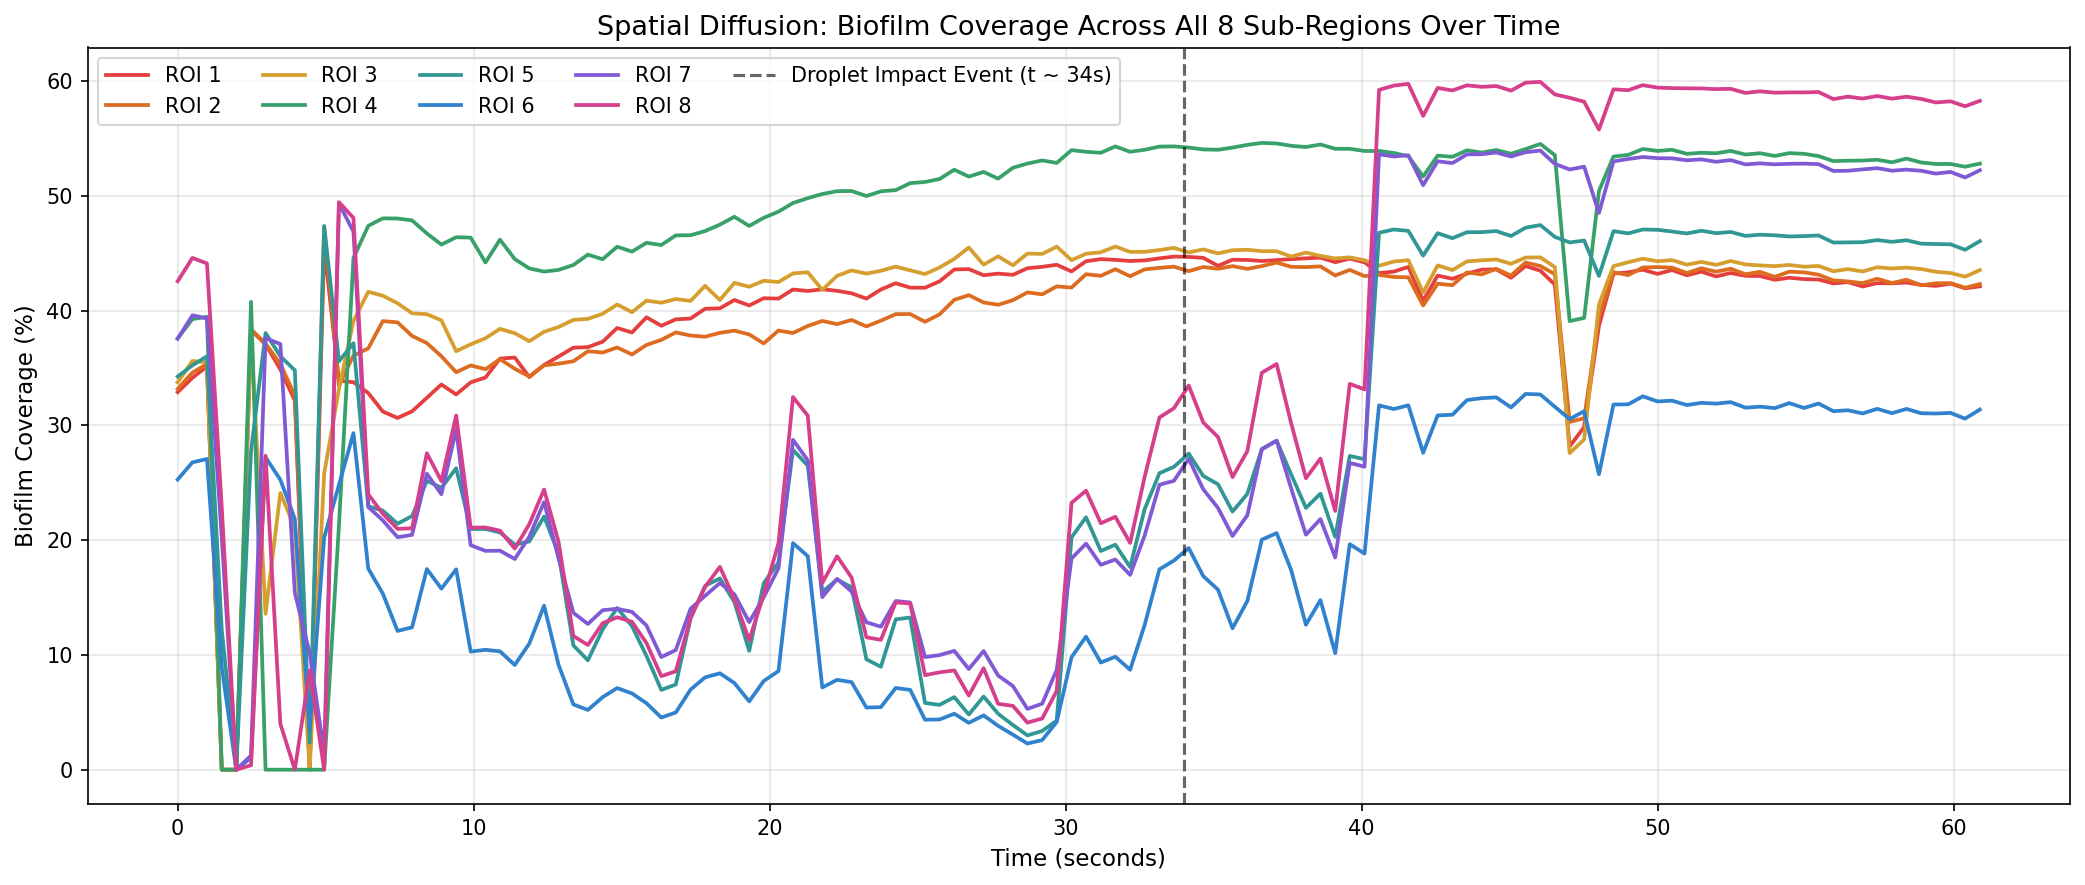

In [7]:
cap = cv2.VideoCapture(video_path)

H_patch, W_patch = ry2 - ry1, rx2 - rx1
tile_h = H_patch // 2
tile_w = W_patch // 4

roi_timeseries = {f"ROI {r*4 + c + 1}": [] for r in range(2) for c in range(4)}

for idx, f_num in enumerate(target_frames):
    t_sec = f_num / fps
    cap.set(cv2.CAP_PROP_POS_FRAMES, f_num)
    ret, frame = cap.read()
    if not ret: break
    
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    kp_curr, des_curr = sift.detectAndCompute(gray, None)
    
    M = last_valid_M
    if des_curr is not None and len(kp_curr) >= 4:
        matches = bf.knnMatch(des_curr, des0, k=2)
        good = [m for m, n in matches if m.distance < 0.75 * n.distance]
        if len(good) >= 4:
            src = np.float32([kp_curr[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([kp0[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            M_est, _ = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC)
            if M_est is not None: M = M_est
            
    warped = cv2.warpAffine(gray, M, (width, height), flags=cv2.INTER_LINEAR, borderValue=255)
    patch = warped[ry1:ry2, rx1:rx2]
    
    for r in range(2):
        for c in range(4):
            roi_key = f"ROI {r*4 + c + 1}"
            tile = patch[r*tile_h:(r+1)*tile_h, c*tile_w:(c+1)*tile_w]
            cov = (np.sum(tile <= 84) / tile.size) * 100
            roi_timeseries[roi_key].append(cov)

cap.release()

# Plot 8 ROI curves
plt.figure(figsize=(14, 6))
colors = ['#e53e3e', '#dd6b20', '#d69e2e', '#38a169', '#319795', '#3182ce', '#805ad5', '#d53f8c']

for idx, (roi_name, vals) in enumerate(roi_timeseries.items()):
    plt.plot(df_ts['Timestamp (s)'][:len(vals)], vals, label=roi_name, color=colors[idx], lw=1.8)

plt.axvline(34, color='black', linestyle='--', alpha=0.6, label='Droplet Impact Event (t ~ 34s)')
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Biofilm Coverage (%)', fontsize=11)
plt.title('Spatial Diffusion: Biofilm Coverage Across All 8 Sub-Regions Over Time', fontsize=13)
plt.legend(ncol=5, loc='upper left', frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 6. CSV Dataset Export & Statistical Summary
The complete time-series dataset is exported to `video_biofilm_timeseries.csv` for use in thesis tables, Excel analysis, and statistical plotting.


In [8]:
output_csv = 'video_biofilm_timeseries.csv'
df_ts.to_csv(output_csv, index=False)
print(f"Time-series dataset successfully saved to: {output_csv}")

# Key Metrics Extraction
baseline_cov = df_ts[df_ts['Timestamp (s)'] < 30]['Biofilm Coverage (0-84) %'].mean()
peak_cov = df_ts[df_ts['Timestamp (s)'] > 48]['Biofilm Coverage (0-84) %'].mean()
max_rate = df_ts['Rate dC/dt (%/s)'].max()
t_max_rate = df_ts.loc[df_ts['Rate dC/dt (%/s)'].idxmax(), 'Timestamp (s)']

print("\n=== TIME-SERIES EXPERIMENT SUMMARY ===")
print(f"Pre-Drop Baseline Coverage:  {baseline_cov:.2f}% (t = 0s to 30s)")
print(f"Post-Drop Plateau Coverage:   {peak_cov:.2f}% (t = 48s to 61s)")
print(f"Net Dynamic Expansion:       +{peak_cov - baseline_cov:.2f}% absolute change")
print(f"Maximum Expansion Velocity:  +{max_rate:.2f}% per second at t = {t_max_rate:.1f}s")
print(f"Stabilization Range:         dx: [{df_ts['dx (px)'].min():.1f}, {df_ts['dx (px)'].max():.1f}] px | dy: [{df_ts['dy (px)'].min():.1f}, {df_ts['dy (px)'].max():.1f}] px")


Time-series dataset successfully saved to: video_biofilm_timeseries.csv

=== TIME-SERIES EXPERIMENT SUMMARY ===
Pre-Drop Baseline Coverage:  26.82% (t = 0s to 30s)
Post-Drop Plateau Coverage:   46.42% (t = 48s to 61s)
Net Dynamic Expansion:       +19.60% absolute change
Maximum Expansion Velocity:  +24.52% per second at t = 5.5s
Stabilization Range:         dx: [-15.0, 713.0] px | dy: [-224.2, 111.3] px
